# 🌱 Clasificación de enfermedades en plantas

Este proyecto consiste en el desarrollo de un modelo de CNN para clasificar enfermedades en plantas a partir de imágenes.  
El dataset incluye diferentes cultivos y estados de salud, lo que permite entrenar un modelo capaz de identificar patrones visuales y distinguir entre plantas sanas y enfermas.

# 🌱 Clases del dataset

| Cultivo | Clase original | Traducción |
|--------|--------------|-----------|
| 🌶️ Pimiento | Pepper__bell___Bacterial_spot | Mancha bacteriana |
| 🌶️ Pimiento | Pepper__bell___healthy | Saludable |
| 🥔 Papa | Potato___Early_blight | Tizón temprano |
| 🥔 Papa | Potato___Late_blight | Tizón tardío |
| 🥔 Papa | Potato___healthy | Saludable |
| 🍅 Tomate | Tomato_Bacterial_spot | Mancha bacteriana |
| 🍅 Tomate | Tomato_Early_blight | Tizón temprano |
| 🍅 Tomate | Tomato_Late_blight | Tizón tardío |
| 🍅 Tomate | Tomato_Leaf_Mold | Moho de la hoja |
| 🍅 Tomate | Tomato_Septoria_leaf_spot | Mancha por Septoria |
| 🍅 Tomate | Tomato_Spider_mites_Two_spotted_spider_mite | Ácaros |
| 🍅 Tomate | Tomato__Target_Spot | Mancha objetivo |
| 🍅 Tomate | Tomato__Tomato_YellowLeaf__Curl_Virus | Virus hoja amarilla |
| 🍅 Tomate | Tomato__Tomato_mosaic_virus | Virus mosaico |
| 🍅 Tomate | Tomato_healthy | Saludable |

In [1]:
# Libreria para cargar nuestro drive
from google.colab import drive
# Cargamos nuestro drive en nuestro notebook
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
os.chdir('/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades')

In [10]:
import pandas as pd

ruta = "/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades/ndf_final.csv"

ndf = pd.read_csv(ruta)

print(ndf.head())

                                           filepaths  \
0  /content/drive/MyDrive/Proyectos/Proyecto_Plan...   
1  /content/drive/MyDrive/Proyectos/Proyecto_Plan...   
2  /content/drive/MyDrive/Proyectos/Proyecto_Plan...   
3  /content/drive/MyDrive/Proyectos/Proyecto_Plan...   
4  /content/drive/MyDrive/Proyectos/Proyecto_Plan...   

                          labels  
0  Pepper__bell___Bacterial_spot  
1  Pepper__bell___Bacterial_spot  
2  Pepper__bell___Bacterial_spot  
3  Pepper__bell___Bacterial_spot  
4  Pepper__bell___Bacterial_spot  


In [11]:
print(ndf['labels'].value_counts())

labels
Pepper__bell___Bacterial_spot                  500
Pepper__bell___healthy                         500
Potato___Early_blight                          500
Potato___Late_blight                           500
Potato___healthy                               500
Tomato_Bacterial_spot                          500
Tomato_Early_blight                            500
Tomato_Late_blight                             500
Tomato_Leaf_Mold                               500
Tomato_Septoria_leaf_spot                      500
Tomato_Spider_mites_Two_spotted_spider_mite    500
Tomato__Target_Spot                            500
Tomato__Tomato_YellowLeaf__Curl_Virus          500
Tomato__Tomato_mosaic_virus                    500
Tomato_healthy                                 500
Name: count, dtype: int64


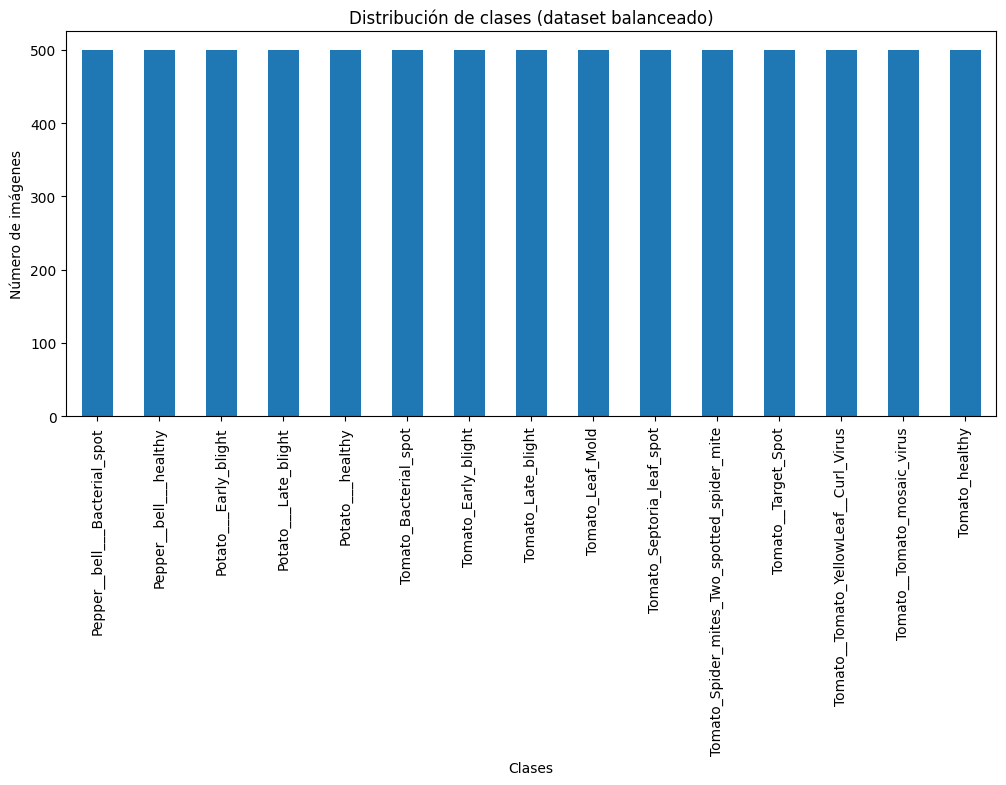

In [12]:
import matplotlib.pyplot as plt

counts = ndf['labels'].value_counts().sort_index()

plt.figure(figsize=(12,5))
counts.plot(kind='bar')

plt.title("Distribución de clases (dataset balanceado)")
plt.xlabel("Clases")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=90)

plt.show()

# Descarga del Dataset

In [ ]:
import os

# DESCARGAR EL DATASET DE 15 CLASES
!pip install -q kaggle
!kaggle datasets download -d emmarex/plantdisease

# DESCOMPRIMIR
!unzip -q plantdisease.zip

Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:42<00:00, 16.2MB/s]



In [ ]:
import os

# Ruta donde descomprimiste el dataset
# Ajusta si la ruta es diferente en tu Drive
path_raiz = '/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades/PlantVillage'

if os.path.exists(path_raiz):
    directorios = [d for d in os.listdir(path_raiz) if os.path.isdir(os.path.join(path_raiz, d))]
    print(f"Total de carpetas encontradas: {len(directorios)}\n")

    total_general = 0
    for carpeta in sorted(directorios):
        ruta_carpeta = os.path.join(path_raiz, carpeta)
        n_imagenes = len([f for f in os.listdir(ruta_carpeta) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        total_general += n_imagenes
        print(f"📂 {carpeta.ljust(45)} | 🖼️ {n_imagenes} imágenes")

    print(f"\n✅ TOTAL GENERAL DE IMÁGENES: {total_general}")
else:
    print("❌ No se encuentra la carpeta. Revisa si el unzip se hizo dentro de otra subcarpeta.")

Total de carpetas encontradas: 15

📂 Pepper__bell___Bacterial_spot                 | 🖼️ 997 imágenes
📂 Pepper__bell___healthy                        | 🖼️ 1478 imágenes
📂 Potato___Early_blight                         | 🖼️ 1000 imágenes
📂 Potato___Late_blight                          | 🖼️ 1000 imágenes
📂 Potato___healthy                              | 🖼️ 152 imágenes
📂 Tomato_Bacterial_spot                         | 🖼️ 2127 imágenes
📂 Tomato_Early_blight                           | 🖼️ 1000 imágenes
📂 Tomato_Late_blight                            | 🖼️ 1909 imágenes
📂 Tomato_Leaf_Mold                              | 🖼️ 952 imágenes
📂 Tomato_Septoria_leaf_spot                     | 🖼️ 1771 imágenes
📂 Tomato_Spider_mites_Two_spotted_spider_mite   | 🖼️ 1676 imágenes
📂 Tomato__Target_Spot                           | 🖼️ 1404 imágenes
📂 Tomato__Tomato_YellowLeaf__Curl_Virus         | 🖼️ 3208 imágenes
📂 Tomato__Tomato_mosaic_virus                   | 🖼️ 373 imágenes
📂 Tomato_healthy               

# Inspección Visual del Dataset 🖼️





In [ ]:
import matplotlib.pyplot as plt
import os
import cv2
import random

# Define tu ruta definitiva aquí
path_raiz = '/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades/PlantVillage'
clases = sorted(os.listdir(path_raiz))

plt.figure(figsize=(20, 12))

for i, clase in enumerate(clases):
    # Elegir una imagen al azar de la carpeta
    folder = os.path.join(path_raiz, clase)
    img_name = random.choice(os.listdir(folder))
    img_path = os.path.join(folder, img_name)

    # Leer y convertir
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Mostrar en el mosaico
    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{clase}\n{img.shape}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# Análisis de Balanceo de Clases

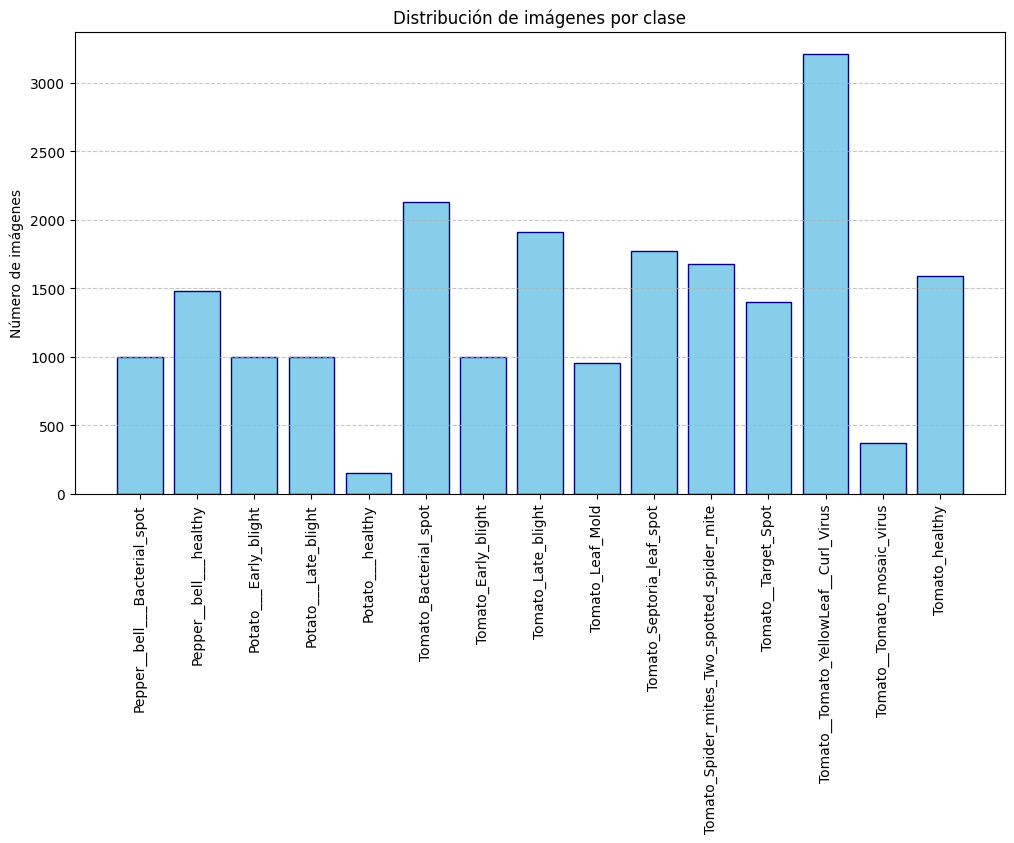

In [ ]:
conteo = {}
for clase in clases:
    ruta = os.path.join(path_raiz, clase)
    conteo[clase] = len(os.listdir(ruta))

plt.figure(figsize=(12,6))
plt.bar(conteo.keys(), conteo.values(), color='skyblue', edgecolor='navy')
plt.xticks(rotation=90)
plt.title("Distribución de imágenes por clase")
plt.ylabel("Número de imágenes")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Verificación de Dimensiones

In [ ]:
anchos = []
altos = []

# Muestreo de 50 imágenes por clase para agilizar
for clase in clases:
    carpeta = os.path.join(path_raiz, clase)
    for img_name in os.listdir(carpeta)[:5]:
        img_path = os.path.join(carpeta, img_name)
        img = cv2.imread(img_path)
        if img is not None:
            h, w, _ = img.shape
            altos.append(h)
            anchos.append(w)

print(f"Altura promedio: {sum(altos)/len(altos):.2f} px")
print(f"Ancho promedio: {sum(anchos)/len(anchos):.2f} px")

Altura promedio: 256.00 px
Ancho promedio: 256.00 px


# Mapa de Calor

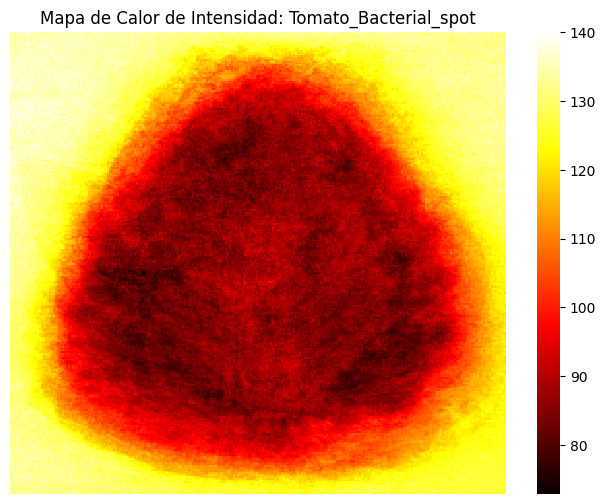

In [ ]:
import numpy as np
import seaborn as sns

def generar_heatmap(clase_nombre, n_muestras=50):
    ruta_clase = os.path.join(path_raiz, clase_nombre)
    imagenes = [f for f in os.listdir(ruta_clase) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:n_muestras]

    # Acumulador para las imágenes en escala de grises
    acumulador = np.zeros((256, 256), dtype=np.float32)

    for img_name in imagenes:
        img = cv2.imread(os.path.join(ruta_clase, img_name), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (256, 256))
        # Normalizamos y sumamos
        acumulador += img / n_muestras

    return acumulador

# Elegimos una clase interesante, por ejemplo, una de tomate con manchas
clase_test = 'Tomato_Bacterial_spot'
heatmap_data = generar_heatmap(clase_test)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, cmap='hot')
plt.title(f"Mapa de Calor de Intensidad: {clase_test}")
plt.axis('off')
plt.show()

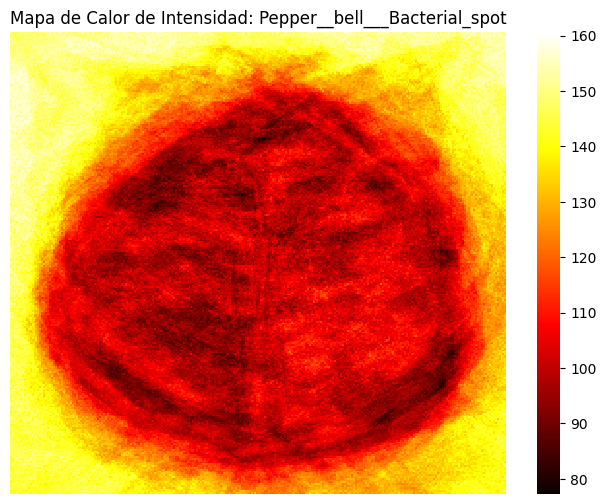

In [ ]:
import numpy as np
import seaborn as sns

def generar_heatmap(clase_nombre, n_muestras=50):
    ruta_clase = os.path.join(path_raiz, clase_nombre)
    imagenes = [f for f in os.listdir(ruta_clase) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:n_muestras]

    # Acumulador para las imágenes en escala de grises
    acumulador = np.zeros((256, 256), dtype=np.float32)

    for img_name in imagenes:
        img = cv2.imread(os.path.join(ruta_clase, img_name), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (256, 256))
        # Normalizamos y sumamos
        acumulador += img / n_muestras

    return acumulador

# Elegimos una clase interesante, por ejemplo, una de tomate con manchas
clase_test = 'Pepper__bell___Bacterial_spot'
heatmap_data = generar_heatmap(clase_test)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, cmap='hot')
plt.title(f"Mapa de Calor de Intensidad: {clase_test}")
plt.axis('off')
plt.show()